# Read merged distributions

You'll merge the duration sketches of every call of the matrix-vector product over all runs of a setting, and plot the distribution of one call as the processes per node grow.
It takes about 10 minutes of your time on a compute node.

## Before you start

Run the kernel inside an allocation and open the full sweep, as in [Measure the flop rate as processes share a node](06-flop-rate-as-processes-share-a-node.ipynb).

In [1]:
from dftracer.utils import Indexer, TraceViewer, col

TRACE = "/usr/workspace/genesis-wisdom/dftracer-traces/genesis-sweep/genesis.pfw.gz"
INDEX = "../data/full-index"
with Indexer(files=[TRACE], index_dir=INDEX) as ix:
    ix.ensure_indexed()
    runs = ix.rowset("runs")
tv = TraceViewer(TRACE, INDEX)
print(runs.shape)

(9624, 10)


In [2]:
import os

import matplotlib.pyplot as plt

os.makedirs("../figures", exist_ok=True)

## 1. Why merge the sketches

`dur.p50` of a record is the median call of one call path in one run.
The median of several runs' medians is not the median of all their calls, because each run has its own number of calls.
`dur.sketch` holds the whole distribution of the record's calls, and sketches merge without loss of their accuracy, so a merged sketch gives the quantiles of all the calls together.
`col("dur.sketch").sketch_quantile(q)` does that merge for each group and reads the quantile `q`.

## 2. Merge one call over the runs of each setting

Take `hypre_CSRMatrixMatvecOutOfPlace` at depth 6, inside the relaxation of the multigrid cycle, for amg `p1_n64x64x32` on one matrix node.

In [3]:
func = tv.filter(
    (col("gtype") == "func") & (col("name") == "hypre_CSRMatrixMatvecOutOfPlace") & (col("depth") == 6)
).collect().merge(runs, on="run")
func = func[(func["app"] == "amg") & (func["system"] == "matrix") & (func["unique_input"] == "p1_n64x64x32") & (func["nodes"] == 1)]
Q = [0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
quantiles = {f"q{int(q * 100):02d}": col("dur.sketch").sketch_quantile(q) for q in Q}
dist = func.groupby("ppn").agg(calls=col("count").sum(), **quantiles)
print(dist[["ppn", "calls", "q01", "q50", "q99"]])

   ppn  calls          q01          q50           q99
0    1    160  3198.121927  3198.121927   3328.644197
1    2    672   141.205322   247.208888   3464.493363
2    4   1344   159.209192   550.188171   4493.244622
3    8   2816   247.208888   497.829184   5168.485681
4   16   5632   314.266603  1107.968772   8521.534313
5   32  11683   113.319094  1043.443607  13771.653828
6   64  24360   111.075151  1107.968772  13498.947812


The quantiles are in microseconds.
`calls` counts every call over all processes and runs of the setting.
The calls grow faster than the processes, and their durations spread over two orders of magnitude from 2 processes on, so one call path holds calls of very different sizes.

## 3. Compare with the median of medians

In [4]:
both = func[["ppn", "dur.p50"]].groupby("ppn").median().merge(dist[["ppn", "q50"]], on="ppn")
print(both)

   ppn      dur.p50          q50
0    1  3230.426189  3198.121927
1    2   237.705423   247.208888
2    4   438.640337   550.188171
3    8   488.068785   497.829184
4   16   972.672870  1107.968772
5   32  1033.112482  1043.443607
6   64  1119.160376  1107.968772


The two medians agree within a few percent at most settings, but at 4 processes the median of all calls is 550 microseconds and the median of the runs' medians 439.
The merged sketch gives the first one, which counts every call once.

## 4. Plot the distribution of one call

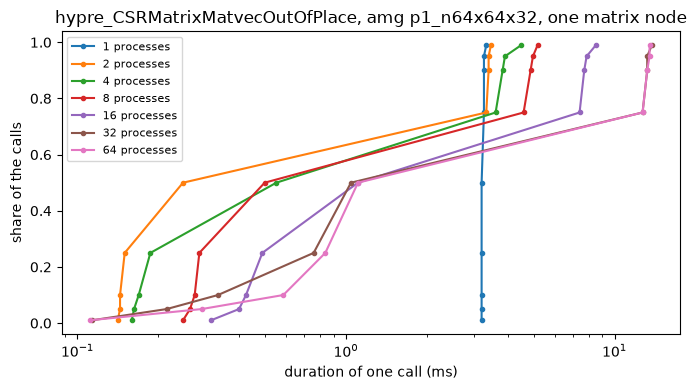

In [5]:
d = dist.to_pandas()
fig, ax = plt.subplots(figsize=(7, 4))
for _, row in d.iterrows():
    ax.plot([row[f"q{int(q * 100):02d}"] / 1e3 for q in Q], Q, marker=".", label=f"{int(row['ppn'])} processes")
ax.set_xscale("log")
ax.set_xlabel("duration of one call (ms)")
ax.set_ylabel("share of the calls")
ax.set_title("hypre_CSRMatrixMatvecOutOfPlace, amg p1_n64x64x32, one matrix node")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("../figures/matvec-distribution.png", dpi=120)
plt.show()

## What you built

You merged the sketches of one call path over runs and read the quantiles of all its calls, which the medians of single runs can't give.

- Next: [Measure the scaling efficiency](11-scaling-efficiency.ipynb)
- The same merge in duql, `quantile(merge(dur.sketch), q)`: [duql reference](https://dftracer.readthedocs.io/projects/utils/en/latest/reference/duql.html)